<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/21-responsible-and-production-ai/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 21: Responsible and Production AI

A model with a good test score is not yet a good system. Before it's used to make decisions about people, you need to know whom it fails, why it decides what it decides, and what it reveals about the people in its training data. And once it's running, you need to know which version is live, how it was made, and whether the world it was trained on still matches the world it's working in.

This last module covers both halves:

**Part A: Responsible AI**

1. Who is in the data
2. A model to examine
3. Measuring fairness
4. Why you can't satisfy every definition
5. Does removing the sensitive attribute help?
6. Mitigation and its trade-offs
7. Interpretability: global explanations
8. Interpretability: Shapley values
9. Privacy

**Part B: Production**

10. Experiment tracking
11. Packaging a model with its model card
12. Serving and containers
13. Monitoring

The data for Part A is the **Adult** census dataset: 32,561 people from the 1994 United States census, with the task of predicting whether a person earns more than $50,000 a year. It's one of the most studied datasets in fairness research, precisely because a model trained on it inherits the inequalities of its time.

In [1]:
import hashlib
import importlib.util
import itertools
import json
import math
import platform
import subprocess
import sys
import time
from pathlib import Path

for package in ["fastapi", "httpx"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import joblib
import numpy as np
import pandas as pd
import sklearn
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/21-responsible-and-production-ai/data/adult.csv.gz"
local = Path("data/adult.csv.gz")
adult = pd.read_csv(local if local.exists() else DATA_URL)
WORK = Path("work")
WORK.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__, "  pandas", pd.__version__)
print(adult.shape)

scikit-learn 1.9.1   pandas 3.0.5
(32561, 15)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

# Part A: Responsible AI

## 1. Who is in the data

Every audit starts by looking at who the data describes, and how the outcome differs between groups. Here are the share of people earning over $50,000 by sex and by race:

In [3]:
adult["high_income"] = (adult["income"] == ">50K").astype(int)
for column in ["sex", "race"]:
    table = adult.groupby(column)["high_income"].agg(people="size", share_high_income="mean")
    table["share_of_data"] = table["people"] / len(adult)
    print(table.sort_values("people", ascending=False).round(3), "\n")

        people  share_high_income  share_of_data
sex                                             
Male     21790              0.306          0.669
Female   10771              0.109          0.331 

                    people  share_high_income  share_of_data
race                                                        
White                27816              0.256          0.854
Black                 3124              0.124          0.096
Asian-Pac-Islander    1039              0.266          0.032
Amer-Indian-Eskimo     311              0.116          0.010
Other                  271              0.092          0.008 



Two things stand out, and both shape everything that follows.

- **Base rates differ a lot.** About 31% of the men earn over $50,000, against 11% of the women. That gap is a fact about the United States in 1994 (and the way the census recorded income for couples), not a property of the people; a model that learns from it will learn the gap.
- **Some groups are small.** There are only a few hundred people in two of the race categories. Any measurement for those groups will be noisy, and a model has little data to learn them from.

Also note what the data can't tell you: sex is recorded as two categories, race as five, and both as the census defined them at the time. Real people don't always fit those boxes. Fairness analysis needs group labels, but it should never pretend they're more precise than they are.

## 2. A model to examine

A gradient-boosting classifier (Module 14) predicts high income from twelve columns. Sex and race are among them for now; Section 5 asks what happens without them.

In [4]:
CATEGORICAL = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
NUMERIC = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
FEATURES = CATEGORICAL + NUMERIC

X = adult[FEATURES].astype({c: float for c in NUMERIC})          # floats: some inspection tools refuse integer columns
y = adult["high_income"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)


def make_model(categorical=CATEGORICAL, numeric=NUMERIC):
    encode = ColumnTransformer(
        [("categories", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), categorical)],
        remainder="passthrough")
    model = HistGradientBoostingClassifier(categorical_features=list(range(len(categorical))), max_iter=200, random_state=0)
    return make_pipeline(encode, model)


model = make_model().fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)
print(f"accuracy {accuracy_score(y_test, pred_test):.3f}   ROC AUC {roc_auc_score(y_test, p_test):.3f}   "
      f"(always guessing 'no': {1 - y_test.mean():.3f})")

accuracy 0.874   ROC AUC 0.927   (always guessing 'no': 0.759)


A good model by the usual measures. Now the questions that overall accuracy can't answer.

## 3. Measuring fairness

There are many definitions of a "fair" classifier, and they measure different things. The four most common compare groups on:

| definition | compares | the question it asks |
|---|---|---|
| **demographic parity** | selection rate: the share predicted positive | do groups get the positive outcome equally often? |
| **equal opportunity** | true positive rate (recall) | among people who really earn over $50,000, are they recognised equally often? |
| **equalised odds** | true positive rate **and** false positive rate | are both kinds of mistake equally common? |
| **predictive parity** | precision | when the model says "yes", is it equally often right? |

In [5]:
def group_report(y_true, y_pred, groups, probabilities=None):
    rows = {}
    y_true, y_pred, groups = np.asarray(y_true), np.asarray(y_pred), np.asarray(groups)
    for g in pd.unique(groups):
        k = groups == g
        t, p = y_true[k], y_pred[k]
        row = {"people": int(k.sum()), "base rate": t.mean(), "selection rate": p.mean(),
               "TPR": p[t == 1].mean() if (t == 1).any() else np.nan,
               "FPR": p[t == 0].mean() if (t == 0).any() else np.nan,
               "precision": t[p == 1].mean() if (p == 1).any() else np.nan}
        if probabilities is not None:
            row["mean probability"] = np.asarray(probabilities)[k].mean()
        rows[g] = row
    return pd.DataFrame(rows).T


report = group_report(y_test, pred_test, X_test["sex"], p_test)
print(report.round(3))

        people  base rate  selection rate    TPR    FPR  precision  \
Female  3240.0      0.108           0.081  0.599  0.018      0.798   
Male    6529.0      0.307           0.255  0.657  0.077      0.790   

        mean probability  
Female             0.112  
Male               0.302  


Read it row by row:

- **Selection rate**: men are predicted to be high earners about three times as often as women. Demographic parity is far from satisfied, but most of that gap matches the base rates in the data.
- **TPR**: among real high earners, the model recognises a somewhat smaller share of the women.
- **FPR**: among people who aren't high earners, men are wrongly flagged several times as often as women.
- **Precision**: when the model says "high income", it's right about equally often for both.

So is the model fair? That depends on which definition you think matters for the use, and as the next section shows, it can't satisfy them all.

The same report by race shows another practical problem: groups with a few hundred people have rates that would move noticeably with a different random split.

In [6]:
print(group_report(y_test, pred_test, X_test["race"]).round(3).sort_values("people", ascending=False))

                    people  base rate  selection rate    TPR    FPR  precision
White               8386.0      0.257           0.212  0.655  0.059      0.794
Black                937.0      0.115           0.083  0.574  0.019      0.795
Asian-Pac-Islander   293.0      0.242           0.201  0.577  0.081      0.695
Amer-Indian-Eskimo    82.0      0.098           0.061  0.625  0.000      1.000
Other                 71.0      0.085           0.070  0.500  0.031      0.600


## 4. Why you can't satisfy every definition

A famous result (Kleinberg, Mullainathan and Raghavan, and separately Chouldechova, both in 2016) says that when two groups have **different base rates**, a classifier that isn't perfect can't have equal precision (or be equally calibrated) for both groups **and** equal true and false positive rates. You have to choose.

The plot below shows why, for this model. On the left, the predicted probabilities are **calibrated** for both groups: among people given a probability of about 0.3, about 30% are high earners, whether they're men or women. On the right, the probabilities of the two groups are distributed very differently, because the base rates are. With one threshold for everyone, more men's probabilities are above it, and that produces both the higher selection rate and the higher false positive rate for men.

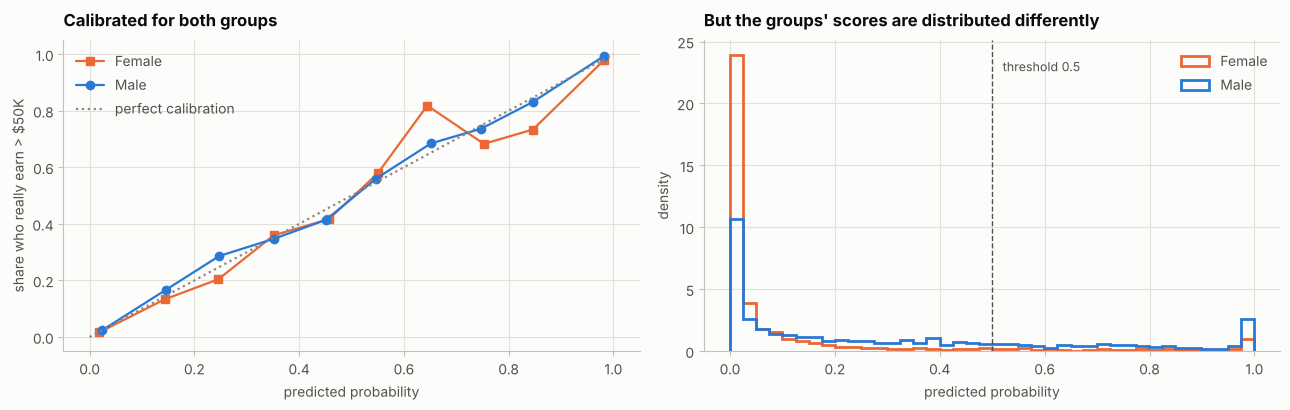

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 11)
for g, color, marker in [("Female", PALETTE[1], "s"), ("Male", PALETTE[0], "o")]:
    k = (X_test["sex"] == g).values
    which = np.digitize(p_test[k], bins[1:-1])
    centres = [p_test[k][which == b].mean() for b in range(10) if (which == b).sum() >= 20]
    observed = [y_test.values[k][which == b].mean() for b in range(10) if (which == b).sum() >= 20]
    axes[0].plot(centres, observed, marker=marker, color=color, label=g)
    axes[1].hist(p_test[k], bins=40, density=True, histtype="step", linewidth=2, color=color, label=g)
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", label="perfect calibration")
axes[0].set_xlabel("predicted probability")
axes[0].set_ylabel("share who really earn > $50K")
axes[0].set_title("Calibrated for both groups")
axes[1].axvline(0.5, color=INK_2, linestyle="--", linewidth=1)
axes[1].text(0.52, axes[1].get_ylim()[1] * 0.9, "threshold 0.5", color=INK_2, fontsize=9)
axes[1].set_xlabel("predicted probability")
axes[1].set_ylabel("density")
axes[1].set_title("But the groups' scores are distributed differently")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

(The women's line wobbles at high probabilities because few women get such scores, so each point there rests on a small number of people.)

Which definition to aim for is a decision about values and about the use, not a technical detail:

- For a **loan**, a lender might care most that a "yes" means the same risk whoever gets it (predictive parity, calibration).
- For finding people who **qualify for help**, equal opportunity matters most: qualified people in every group should be found equally often.
- For a **screening** step where false alarms are costly or stigmatising, equal false positive rates matter.

Many countries' laws also restrict which attributes may be used and how; that's a question for lawyers, not for a model. The technical job is to measure all of these, report them clearly, and make the trade-offs visible to the people who decide.

## 5. Does removing the sensitive attribute help?

A common first instinct is "just don't give the model the sex column". It rarely works, because other columns carry the same information. Here `relationship` contains "Husband" and "Wife", and occupation and hours worked differ between groups too. How well can the **other** eleven columns predict a person's sex?

In [8]:
without_sex = [c for c in CATEGORICAL if c != "sex"]
sex_detector = make_model(categorical=without_sex).fit(X_train.drop(columns="sex"), X_train["sex"] == "Female")
auc = roc_auc_score(X_test["sex"] == "Female", sex_detector.predict_proba(X_test.drop(columns="sex"))[:, 1])
print(f"predicting sex from the other columns: ROC AUC {auc:.3f}")

blind_model = make_model(categorical=without_sex).fit(X_train.drop(columns="sex"), y_train)
p_blind = blind_model.predict_proba(X_test.drop(columns="sex"))[:, 1]
print("\nmodel without the sex column:")
print(group_report(y_test, (p_blind >= 0.5).astype(int), X_test["sex"]).round(3))

predicting sex from the other columns: ROC AUC 0.935



model without the sex column:
        people  base rate  selection rate    TPR    FPR  precision
Female  3240.0      0.108           0.085  0.602  0.022      0.764
Male    6529.0      0.307           0.253  0.648  0.079      0.785


The other columns predict sex almost perfectly, and the "blind" model's group numbers barely change. Columns that stand in for a sensitive attribute are called **proxies**. Removing the attribute also has a cost: you can no longer measure the model's behaviour by group without keeping the attribute somewhere for auditing. "Fairness through unawareness" usually gives the appearance of fairness, not the substance.

## 6. Mitigation and its trade-offs

If a gap matters for the use, there are three places to act:

- **Before training**: collect better or more representative data; reweight the training data so that group and outcome are independent (Exercise 8).
- **During training**: add a fairness constraint to the model's objective (libraries such as Fairlearn do this).
- **After training**: choose decision thresholds per group.

The last is the simplest to show. Suppose the use calls for **equal opportunity**: the same true positive rate for both groups. We keep the threshold of 0.5 for men, and lower the threshold for women until their true positive rate on the training data matches the men's, then check on the test set. (A real project would choose thresholds on a separate validation set, since training-set rates are optimistic.)

In [9]:
p_train = model.predict_proba(X_train)[:, 1]


def threshold_for_tpr(scores, labels, target):
    """The highest threshold whose true positive rate is at least the target."""
    positives = np.sort(scores[labels == 1])[::-1]
    return positives[int(math.ceil(target * len(positives))) - 1]


men, women = (X_train["sex"] == "Male").values, (X_train["sex"] == "Female").values
target_tpr = (p_train[men & (y_train.values == 1)] >= 0.5).mean()           # the men's TPR at threshold 0.5
thresholds = {"Male": 0.5, "Female": threshold_for_tpr(p_train[women], y_train.values[women], target_tpr)}
print(f"target TPR (men, training data): {target_tpr:.3f}")
print("thresholds:", {g: round(float(t), 3) for g, t in thresholds.items()})
pred_adjusted = np.array([p >= thresholds[g] for p, g in zip(p_test, X_test["sex"])]).astype(int)

comparison = pd.concat({"one threshold (0.5)": group_report(y_test, pred_test, X_test["sex"]),
                        "per-group thresholds": group_report(y_test, pred_adjusted, X_test["sex"])})
print(comparison[["selection rate", "TPR", "FPR", "precision"]].round(3))
print(f"\naccuracy: one threshold {accuracy_score(y_test, pred_test):.3f}, per-group {accuracy_score(y_test, pred_adjusted):.3f}")

target TPR (men, training data): 0.702
thresholds: {'Male': 0.5, 'Female': 0.445}
                             selection rate    TPR    FPR  precision
one threshold (0.5)  Female           0.081  0.599  0.018      0.798
                     Male             0.255  0.657  0.077      0.790
per-group thresholds Female           0.093  0.645  0.026      0.750
                     Male             0.255  0.657  0.077      0.790

accuracy: one threshold 0.874, per-group 0.873


The true positive rates are now closer, as intended: more of the women who really are high earners are recognised. Look at what else moved: with a lower threshold, more women who aren't high earners are flagged too, so their false positive rate rises and their precision falls, and overall accuracy changes slightly. Every mitigation moves some numbers in the wrong direction. That's not a flaw in the method; it's the impossibility result from Section 4 in action. Using different thresholds for different groups is also legally restricted in some settings, which is exactly why these decisions belong to people who can weigh the use, the law and the people affected.

## 7. Interpretability: global explanations

People affected by a model, the people who use it, and regulators increasingly expect to know **why** it decides what it decides. Interpretability methods answer two kinds of question:

- **Global**: what does the model rely on, overall?
- **Local**: why did it give **this** person this score?

**Permutation importance** (introduced in Module 14) shuffles one column at a time in the test data and measures how much the model's performance drops. A column the model depends on hurts a lot when shuffled:

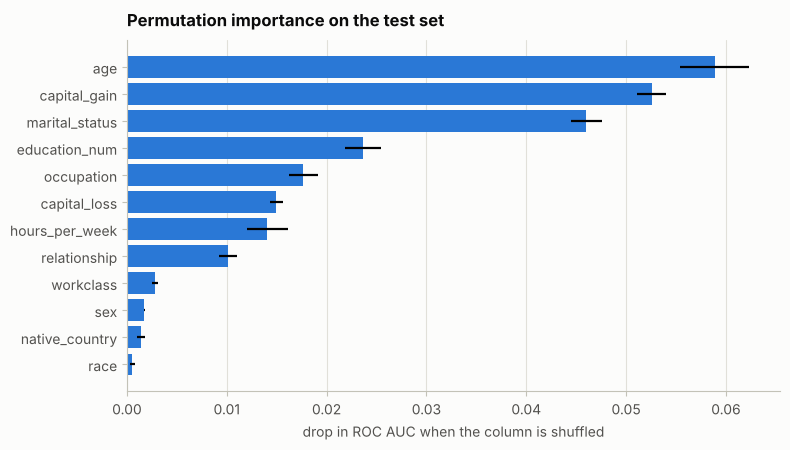

(3 seconds)


In [10]:
start = time.time()
importance = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=0)
order = np.argsort(importance.importances_mean)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(np.array(FEATURES)[order], importance.importances_mean[order], xerr=importance.importances_std[order], color=PALETTE[0])
ax.set_xlabel("drop in ROC AUC when the column is shuffled")
ax.set_title("Permutation importance on the test set")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"({time.time() - start:.0f} seconds)")

Age, capital gains and marital status matter most, followed by education. `relationship` ranks lower than you might expect, because it carries much the same information as `marital_status`: when one is shuffled, the other still stands in for it. `sex` itself ranks low, but that doesn't mean sex doesn't influence the predictions: as Section 5 showed, its information arrives through `relationship` and `marital_status`. Permutation importance tells you what the model **uses**, not what is fair, and correlated columns share their importance in ways that can hide each other.

**Partial dependence** shows how the average prediction changes as one column changes, with everything else held as it is in the data:

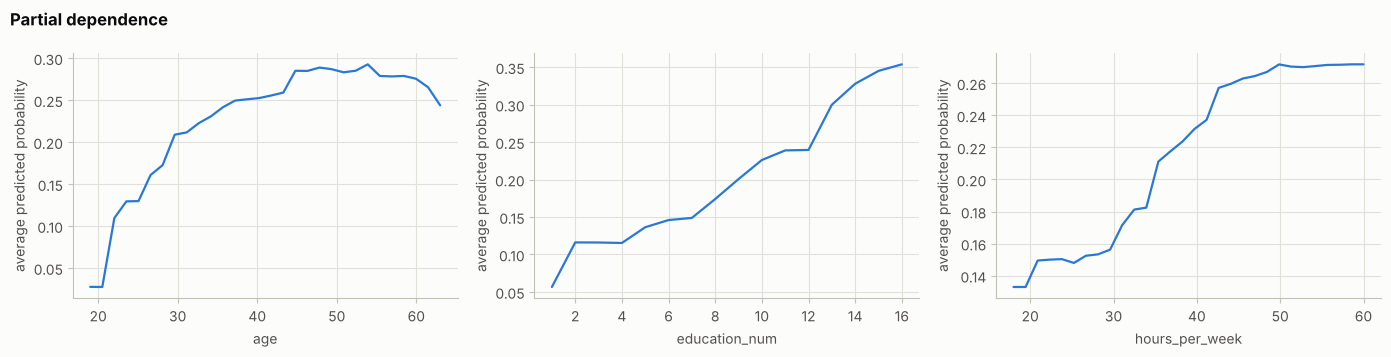

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, column in zip(axes, ["age", "education_num", "hours_per_week"]):
    pd_result = partial_dependence(model, X_test, [column], grid_resolution=30)
    ax.plot(pd_result["grid_values"][0], pd_result["average"][0], color=PALETTE[0])
    ax.set_xlabel(column)
    ax.set_ylabel("average predicted probability")
fig.suptitle("Partial dependence", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

The probability of high income rises through working life and falls again near retirement, rises with years of education, and rises with hours worked up to about 50 a week. These describe the **model**, and through it the patterns in 1994 data; they aren't causal effects. Partial dependence also averages over combinations that may not exist (a 20-year-old with 16 years of education), so read it as a summary, not a law.

## 8. Interpretability: Shapley values

For one person's prediction, the most widely used explanation is the **Shapley value**, from cooperative game theory. Think of the features as players who together produce the prediction. A feature's Shapley value is its average contribution to the prediction, over every possible order in which features could be "added", starting from the average prediction over a **background** sample. The values add up exactly to the difference between this person's prediction and the average.

With twelve features there are only 4,096 subsets, so we can compute them exactly. (The SHAP library uses clever approximations to do the same for models with hundreds of features.)

In [12]:
def shapley_values(predict, person, background):
    """Exact interventional Shapley values for one row (a DataFrame with one row)."""
    columns = list(person.columns)
    d = len(columns)
    subsets = [s for size in range(d + 1) for s in itertools.combinations(range(d), size)]
    frames = []
    for subset in subsets:
        mixed = background.copy()
        for j in subset:                                            # features in the subset take the person's values
            mixed[columns[j]] = person.iloc[0, j]
        frames.append(mixed)
    predictions = predict(pd.concat(frames, ignore_index=True)).reshape(len(subsets), len(background))
    value = dict(zip(subsets, predictions.mean(axis=1)))            # v(S): the average prediction with S fixed
    phi = np.zeros(d)
    for j in range(d):
        for size in range(d):
            weight = math.factorial(size) * math.factorial(d - size - 1) / math.factorial(d)
            for subset in itertools.combinations([i for i in range(d) if i != j], size):
                with_j = tuple(sorted(subset + (j,)))
                phi[j] += weight * (value[with_j] - value[subset])
    return pd.Series(phi, index=columns), value[()]


background = X_train.sample(50, random_state=0)
person = X_test.iloc[[np.argmax(p_test > 0.8)]]
start = time.time()
phi, base_value = shapley_values(lambda data: model.predict_proba(data)[:, 1], person, background)
print(f"computed in {time.time() - start:.0f} seconds")
print(person.T.rename(columns={person.index[0]: "value"}))
print(f"\naverage prediction over the background: {base_value:.3f}")
print(f"this person's prediction:               {model.predict_proba(person)[0, 1]:.3f}")
print(f"base + sum of Shapley values:            {base_value + phi.sum():.3f}")

computed in 3 seconds
                             value
workclass                  Private
marital_status  Married-civ-spouse
occupation         Exec-managerial
relationship               Husband
race                         White
sex                           Male
native_country       United-States
age                           45.0
education_num                 11.0
capital_gain                   0.0
capital_loss                1977.0
hours_per_week                50.0

average prediction over the background: 0.274
this person's prediction:               0.984
base + sum of Shapley values:            0.984


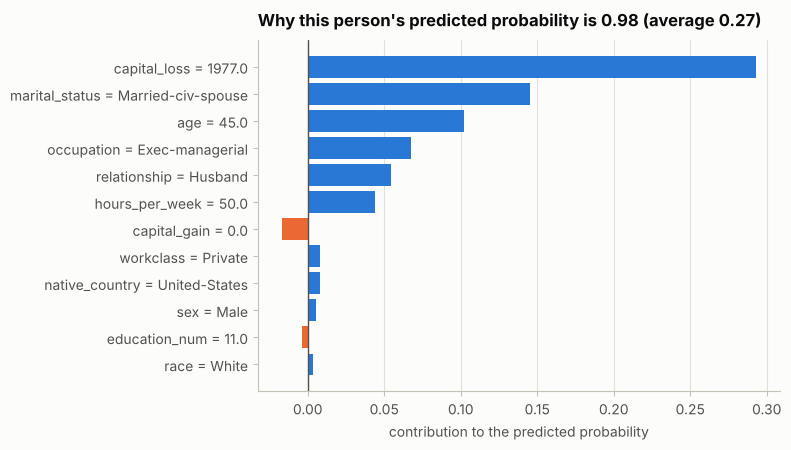

In [13]:
order = phi.abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = [PALETTE[0] if v > 0 else PALETTE[1] for v in phi[order]]
ax.barh([f"{c} = {person.iloc[0][c]}" for c in order], phi[order], color=colors)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("contribution to the predicted probability")
ax.set_title(f"Why this person's predicted probability is {model.predict_proba(person)[0, 1]:.2f} (average {base_value:.2f})")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Each bar is one feature's share of the difference between this person's predicted probability and the average: blue bars push the prediction up, orange ones down, and together they add up exactly to the gap, as the printout confirms.

Explanations like this are also a debugging tool. If an oddly specific value dominates, look at the data: in Adult, for example, all 168 people with a capital loss of exactly $1,977 earn over $50,000, a quirk of the data that a model happily learns and an explanation makes visible.

Shapley values are useful, but know their limits. They depend on the **background** sample (compared with whom?). When features are correlated, mixing one person's values with background values creates unrealistic combinations, and the credit gets split in debatable ways. And an explanation of what the model did is not a justification: a model can give a perfectly explained prediction for a bad reason. For decisions that people have a right to challenge, simple models whose reasoning can be read directly (such as the logistic regression of Module 12) are often the more honest choice.

## 9. Privacy

Training data is about people, and a model can leak it. Three ideas every practitioner should know:

**Removing names isn't anonymisation.** The Adult data has no names, but a combination of ordinary facts can still point to one person. How many people in the dataset are the **only** one with their combination of age, sex, race, country of birth and marital status?

In [14]:
quasi_identifiers = ["age", "sex", "race", "native_country", "marital_status"]
group_sizes = adult.groupby(quasi_identifiers, dropna=False)["age"].transform("size")
print(f"people unique on these five facts: {(group_sizes == 1).sum():,} of {len(adult):,} ({(group_sizes == 1).mean():.1%})")

coarse = adult.assign(age=(adult["age"] // 10) * 10,
                      native_country=np.where(adult["native_country"] == "United-States", "United-States", "Other"))
coarse_sizes = coarse.groupby(quasi_identifiers, dropna=False)["age"].transform("size")
print(f"after grouping ages by decade and countries into two: {(coarse_sizes == 1).sum():,} unique, "
      f"smallest group {coarse_sizes.min()} (this is the dataset's k-anonymity)")

people unique on these five facts: 2,362 of 32,561 (7.3%)
after grouping ages by decade and countries into two: 133 unique, smallest group 1 (this is the dataset's k-anonymity)


Thousands of people are unique on five unremarkable facts, so anyone who knows those facts about a neighbour could find their record and learn their income. **k-anonymity** asks that every combination of such facts is shared by at least `k` records; coarsening the data (age in decades, fewer countries) raises `k`, at the cost of detail. It helps, but it's known to be fragile: combining several released tables, or knowing one unusual fact, can still single people out.

**Differential privacy** gives a mathematical guarantee instead. A differentially private answer is computed with carefully calibrated random noise, so that the result would be almost the same whether or not any one person's record was in the data. For a count, adding noise from a Laplace distribution with scale `1 / epsilon` is enough, where `epsilon` (the **privacy budget**) sets the trade-off: smaller means more privacy and more noise.

In [15]:
rng = np.random.default_rng(0)
true_count = int(((adult["sex"] == "Female") & (adult["high_income"] == 1)).sum())
print(f"true count of women earning over $50K: {true_count}")
for epsilon in [0.01, 0.1, 1.0]:
    noisy = true_count + rng.laplace(0, 1 / epsilon, size=5)
    print(f"epsilon {epsilon:>4}: five noisy answers {np.round(noisy).astype(int)}")

true count of women earning over $50K: 1179
epsilon 0.01: five noisy answers [1211 1117  929  838 1277]
epsilon  0.1: five noisy answers [1196 1181 1185 1180 1199]
epsilon  1.0: five noisy answers [1180 1174 1180 1176 1180]


For a count over thousands of people, the noise at `epsilon = 1` is negligible; for a count of a handful of people, it would swamp the answer, which is exactly the point: small groups are where individuals are exposed. National statistics offices (the 2020 United States census among them) and several technology companies use differential privacy for published statistics, and it can be applied to model training too.

**Models can leak their training data.** An overfitted model is more confident on the examples it was trained on than on new ones, so someone with access to the model can guess whether a given person was in the training set (a **membership inference attack**). Compare a random forest grown without limits with the boosted model:

In [16]:
def membership_auc(fitted, name):
    conf_train = fitted.predict_proba(X_train)[np.arange(len(y_train)), y_train.values]
    conf_test = fitted.predict_proba(X_test)[np.arange(len(y_test)), y_test.values]
    auc = roc_auc_score(np.r_[np.ones(len(conf_train)), np.zeros(len(conf_test))], np.r_[conf_train, conf_test])
    print(f"{name:<34} train accuracy {fitted.score(X_train, y_train):.3f}   test {fitted.score(X_test, y_test):.3f}   "
          f"membership AUC {auc:.3f}")


one_hot = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)], remainder="passthrough")
deep_forest = make_pipeline(one_hot, RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)).fit(X_train, y_train)
membership_auc(deep_forest, "random forest, unlimited depth")
membership_auc(model, "gradient boosting (Section 2)")

random forest, unlimited depth     train accuracy 0.980   test 0.849   membership AUC 0.601


gradient boosting (Section 2)      train accuracy 0.888   test 0.874   membership AUC 0.508


A membership AUC of 0.5 means the attacker can't tell members from non-members; higher means the model's confidence gives them away. The overfitted forest leaks noticeably, the boosted model, whose training and test accuracy are close, much less. Regularisation (Module 12) is a privacy measure as well as a way to generalise. Other good habits: collect only the data you need, keep sensitive attributes separately with restricted access, and never put personal data in a public notebook or repository.

# Part B: Production

## 10. Experiment tracking

Months later, someone will ask: which model is running, what data was it trained on, with which settings, and how good was it? If the answer lives in a notebook's scrolled-away output, nobody knows. **Experiment tracking** records every training run: its parameters, its metrics, a fingerprint of the data, and the library versions.

Tools such as MLflow and Weights & Biases do this with a web interface. The idea fits in a few lines: append one JSON record per run to a file.

In [17]:
RUNS = WORK / "runs.jsonl"
RUNS.unlink(missing_ok=True)


def data_fingerprint(frame):
    return hashlib.sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()[:16]


def log_run(name, params, metrics):
    record = {"run": name, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "params": params, "metrics": metrics,
              "train_data": data_fingerprint(X_train.assign(y=y_train)),
              "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__}}
    with RUNS.open("a") as f:
        f.write(json.dumps(record) + "\n")
    return record


candidates = {
    "logistic regression": (make_pipeline(ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                                                             ("numbers", StandardScaler(), NUMERIC)]),
                                          LogisticRegression(max_iter=2000)), {"model": "LogisticRegression", "C": 1.0}),
    "boosting, learning rate 0.1": (make_model(), {"model": "HistGradientBoosting", "learning_rate": 0.1}),
    "boosting, learning rate 0.3": (make_model(), {"model": "HistGradientBoosting", "learning_rate": 0.3}),
}
for name, (pipeline, params) in candidates.items():
    if "learning_rate" in params:
        pipeline.set_params(histgradientboostingclassifier__learning_rate=params["learning_rate"])
    pipeline.fit(X_train, y_train)
    probs = pipeline.predict_proba(X_test)[:, 1]
    tpr = group_report(y_test, (probs >= 0.5).astype(int), X_test["sex"])["TPR"]
    log_run(name, params, {"roc_auc": round(roc_auc_score(y_test, probs), 4),
                           "accuracy": round(accuracy_score(y_test, probs >= 0.5), 4),
                           "tpr_gap_sex": round(float(tpr.max() - tpr.min()), 4)})

runs = [json.loads(line) for line in RUNS.read_text().splitlines()]
print(pd.DataFrame([{"run": r["run"], **r["metrics"], "data": r["train_data"]} for r in runs]).to_string(index=False))

                        run  roc_auc  accuracy  tpr_gap_sex             data
        logistic regression   0.9056    0.8509       0.0639 016dcd600f9b0ede
boosting, learning rate 0.1   0.9270    0.8741       0.0582 016dcd600f9b0ede
boosting, learning rate 0.3   0.9248    0.8701       0.0403 016dcd600f9b0ede


Each run records the same data fingerprint, so you know they're comparable, and the fairness gap sits next to the accuracy, so it's part of every comparison rather than an afterthought. (Strictly, choosing between models should use validation data rather than the test set, as in Modules 12 to 14; the test set stands in here to keep the example short.)

## 11. Packaging a model with its model card

A model file on its own is a trap (Module 10 showed one that loaded but couldn't predict). Save everything needed to use it correctly: the whole pipeline, the expected inputs, the threshold, and the training details. And write a **model card** (Mitchell and colleagues, 2019): a short document saying what the model is for, what it isn't for, how it was evaluated, and how it performs for different groups.

In [18]:
bundle = {
    "pipeline": model,
    "features": {"categorical": CATEGORICAL, "numeric": NUMERIC},
    "categories": {c: sorted(X_train[c].dropna().unique().tolist()) for c in CATEGORICAL},
    "threshold": 0.5,
    "trained": time.strftime("%Y-%m-%d"),
    "train_data": data_fingerprint(X_train.assign(y=y_train)),
    "versions": {"scikit-learn": sklearn.__version__},
}
joblib.dump(bundle, WORK / "income_model.joblib")

by_sex = group_report(y_test, pred_test, X_test["sex"])
card = f"""# Model card: income classifier (teaching example)

**What it does.** Estimates the probability that a person's yearly income was over $50,000, from 12 census answers.

**Intended use.** Teaching fairness, interpretability and deployment. **Not** for decisions about real people: the data is from 1994,
from one country, and reflects the inequalities of its time.

**Data.** UCI Adult (1994 United States census extract), {len(X_train):,} training and {len(X_test):,} test records.
Training data fingerprint {bundle['train_data']}.

**Performance (test set).** ROC AUC {roc_auc_score(y_test, p_test):.3f}, accuracy {accuracy_score(y_test, pred_test):.3f} at threshold 0.5.

**By sex (test set, threshold 0.5).**

| group | people | selection rate | TPR | FPR | precision |
|---|---|---|---|---|---|
""" + "\n".join(f"| {g} | {int(r['people'])} | {r['selection rate']:.3f} | {r['TPR']:.3f} | {r['FPR']:.3f} | {r['precision']:.3f} |"
                for g, r in by_sex.iterrows()) + """

**Known limitations.** Lower true positive rate and much lower false positive rate for women; groups with few records
(some race categories) have unreliable estimates. Removing the sex column does not remove the gap (proxies).

**Caveats.** Probabilities are calibrated on 1994 data only. Monitor input drift before any reuse.
"""
(WORK / "model_card.md").write_text(card)
print(card)

# Model card: income classifier (teaching example)

**What it does.** Estimates the probability that a person's yearly income was over $50,000, from 12 census answers.

**Intended use.** Teaching fairness, interpretability and deployment. **Not** for decisions about real people: the data is from 1994,
from one country, and reflects the inequalities of its time.

**Data.** UCI Adult (1994 United States census extract), 22,792 training and 9,769 test records.
Training data fingerprint 016dcd600f9b0ede.

**Performance (test set).** ROC AUC 0.927, accuracy 0.874 at threshold 0.5.

**By sex (test set, threshold 0.5).**

| group | people | selection rate | TPR | FPR | precision |
|---|---|---|---|---|---|
| Female | 3240 | 0.081 | 0.599 | 0.018 | 0.798 |
| Male | 6529 | 0.255 | 0.657 | 0.077 | 0.790 |

**Known limitations.** Lower true positive rate and much lower false positive rate for women; groups with few records
(some race categories) have unreliable estimates. Removing the sex column 

Note what the card says plainly: the intended use, the non-intended use, and the known gaps. A model card that only reports a headline accuracy isn't doing its job.

## 12. Serving and containers

Module 11 served a model with **FastAPI**. The same pattern applies here, with two production habits: **validate every input** before it reaches the model, and **test the service** like any other code. `pydantic` describes the expected request and rejects malformed ones automatically.

In [19]:
from typing import Optional

from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field


class Person(BaseModel):
    age: int = Field(ge=17, le=100)
    workclass: Optional[str] = None
    education_num: int = Field(ge=1, le=16)
    marital_status: str
    occupation: Optional[str] = None
    relationship: str
    race: str
    sex: str
    capital_gain: float = Field(ge=0)
    capital_loss: float = Field(ge=0)
    hours_per_week: int = Field(ge=1, le=99)
    native_country: Optional[str] = None


def create_app(bundle):
    app = FastAPI(title="Income model (teaching example)")

    @app.get("/health")
    def health():
        return {"status": "ok", "trained": bundle["trained"], "train_data": bundle["train_data"]}

    @app.post("/predict")
    def predict(person: Person):
        row = person.model_dump()
        for column in ["marital_status", "relationship", "race", "sex"]:
            if row[column] not in bundle["categories"][column]:
                raise HTTPException(status_code=422, detail=f"unknown {column}: {row[column]!r}")
        frame = pd.DataFrame([row])[bundle["features"]["categorical"] + bundle["features"]["numeric"]]
        probability = float(bundle["pipeline"].predict_proba(frame)[0, 1])
        return {"probability": round(probability, 4), "high_income": probability >= bundle["threshold"]}

    return app


client = TestClient(create_app(joblib.load(WORK / "income_model.joblib")))
example = {"age": 45, "workclass": "Private", "education_num": 13, "marital_status": "Married-civ-spouse",
           "occupation": "Exec-managerial", "relationship": "Husband", "race": "White", "sex": "Male",
           "capital_gain": 0, "capital_loss": 0, "hours_per_week": 50, "native_country": "United-States"}

print("health:      ", client.get("/health").json())
print("valid:       ", client.post("/predict", json=example).status_code, client.post("/predict", json=example).json())
print("age 300:     ", client.post("/predict", json={**example, "age": 300}).status_code)
print("missing sex: ", client.post("/predict", json={k: v for k, v in example.items() if k != "sex"}).status_code)
print("unknown race:", client.post("/predict", json={**example, "race": "Martian"}).status_code)

health:       {'status': 'ok', 'trained': '2026-11-19', 'train_data': '016dcd600f9b0ede'}
valid:        200 {'probability': 0.8367, 'high_income': True}
age 300:      422
missing sex:  422
unknown race: 422


Status 200 is a success; 422 means the request was rejected as invalid, with a message saying why, instead of a confusing error or, worse, a silent nonsense prediction.

To run the service anywhere, it's packaged in a **container**: an image holding the code, the model file and exact library versions, which runs the same on a laptop, a server or a cloud service. The recipe is a `Dockerfile`. Here are the files a deployment would need (Docker itself isn't available in Colab, so we only write them):

In [20]:
app_code = '''import joblib
from fastapi import FastAPI
# ... the Person model and the create_app function from the notebook go here ...
app = create_app(joblib.load("income_model.joblib"))
'''
dockerfile = f'''FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py income_model.joblib ./
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
'''
requirements = f"scikit-learn=={sklearn.__version__}\npandas=={pd.__version__}\nfastapi\nuvicorn\njoblib\n"
for name, text in [("app.py", app_code), ("Dockerfile", dockerfile), ("requirements.txt", requirements)]:
    (WORK / name).write_text(text)
print(dockerfile)
print(requirements)

FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py income_model.joblib ./
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

scikit-learn==1.9.1
pandas==3.0.5
fastapi
uvicorn
joblib



With Docker installed, two commands build and run it: `docker build -t income-model .` and `docker run -p 8000:8000 income-model`. Notice that `requirements.txt` pins the **exact** scikit-learn and pandas versions used for training: a model saved with one version of scikit-learn isn't guaranteed to load in another, and the container makes sure the versions travel with the model.

## 13. Monitoring

A deployed model is trained on the past and used in the present. When the incoming data drifts away from the training data, the model's performance can quietly fall, often long before anyone collects the labels needed to measure it. So you watch the **inputs** and the **predictions** all the time, and the **performance** whenever labels arrive.

To see it, we simulate a few weeks of incoming requests. Week 1 looks like the test data. In week 2 the population shifts (the service is used more by older, more educated people). In week 3, on top of that, an upstream system starts sending `capital_gain` in thousands of dollars instead of dollars, a classic data bug.

In [21]:
rng = np.random.default_rng(1)
week1 = X_test.sample(2000, random_state=1)
older = X_test[(X_test["age"] > 40) | (X_test["education_num"] > 12)]
week2 = pd.concat([X_test.sample(1000, random_state=2), older.sample(1000, random_state=2)])
week3 = week2.sample(2000, replace=True, random_state=3).assign(capital_gain=lambda d: d["capital_gain"] / 1000)
weeks = {"week 1": week1, "week 2": week2, "week 3": week3}


def psi(expected, actual, bins=10, edges=None):
    """Population stability index between two samples of a numeric column."""
    if edges is None:
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))     # bins with equal shares of the training data
    edges = np.array(edges, dtype=float)
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))


print(f"share of training rows with no capital gain: {(X_train['capital_gain'] == 0).mean():.1%}")
GAIN_EDGES = [-np.inf, 0.5, 1000, 3000, 5000, 10000, np.inf]     # fixed edges: quantile bins collapse when most values are 0

rows = []
for name, data in weeks.items():
    row = {"week": name}
    for column in ["age", "education_num", "hours_per_week"]:
        row[f"PSI {column}"] = psi(X_train[column], data[column])
    row["PSI capital_gain"] = psi(X_train["capital_gain"], data["capital_gain"], edges=GAIN_EDGES)
    probs = model.predict_proba(data)[:, 1]
    row["PSI prediction"] = psi(p_train, probs)
    row["predicted positive rate"] = (probs >= 0.5).mean()
    rows.append(row)
monitor = pd.DataFrame(rows).set_index("week")
print(monitor.round(3))

share of training rows with no capital gain: 91.5%
        PSI age  PSI education_num  PSI hours_per_week  PSI capital_gain  \
week                                                                       
week 1    0.002              0.003               0.004             0.001   
week 2    0.145              0.050               0.010             0.008   
week 3    0.143              0.048               0.017             0.853   

        PSI prediction  predicted positive rate  
week                                             
week 1           0.007                    0.191  
week 2           0.080                    0.269  
week 3           0.113                    0.247  


The **population stability index** compares the distribution of a column in production with its distribution in training, bin by bin. A common rule of thumb: below 0.1 no meaningful change, 0.1 to 0.25 worth a look, above 0.25 a significant shift. (Exercise 7 builds it.)

One practical catch is visible in the code: bins are usually chosen so that each holds the same share of the training data, but over 90% of people have no capital gain at all, so those bins collapse into one and PSI would always be 0. For columns like that, choose the bin edges yourself.

- **Week 1** is stable everywhere, as it should be.
- **Week 2** shows drift in age (and a smaller shift in education), and the model's predicted positive rate jumps. Nothing is broken: the users have changed. Whether the model is still accurate for them can only be known once their real outcomes arrive.
- **Week 3**'s PSI for `capital_gain` jumps because almost every value is now tiny. This one **is** a bug, and the model quietly treats people with large capital gains as having almost none.

For categorical columns the same idea works with category shares instead of bins, and a statistical test such as the Kolmogorov-Smirnov test (Exercise 12) can back up a PSI alarm:

In [22]:
for name, data in weeks.items():
    result = stats.ks_2samp(X_train["capital_gain"], data["capital_gain"])
    print(f"{name}: capital_gain KS statistic {result.statistic:.3f}, p-value {result.pvalue:.2g}")

week 1: capital_gain KS statistic 0.003, p-value 1
week 2: capital_gain KS statistic 0.016, p-value 0.75
week 3: capital_gain KS statistic 0.085, p-value 6.1e-12


With thousands of requests, tests like this find "significant" differences for tiny shifts too, so in practice teams set thresholds on effect sizes such as PSI and use tests as a second opinion. When labels do arrive, the most important check is the one no input statistic can replace: the model's actual performance, overall **and by group**, compared with the model card.

A monitoring plan worth writing down before going live: which statistics are checked, how often, what thresholds trigger an alert, who receives it, and what happens next (investigate, retrain, roll back).

## Summary

**Responsible AI**

- Look at **who is in the data** and how outcomes differ between groups before modelling.
- Fairness has several definitions (demographic parity, equal opportunity, equalised odds, predictive parity); with different base rates, **they can't all hold at once**. Choosing among them is a decision about the use and its values.
- Removing a sensitive attribute rarely removes its influence, because of **proxies**, and it makes auditing harder.
- Mitigations (better data, reweighting, constraints, per-group thresholds) always trade some numbers for others.
- **Permutation importance** and **partial dependence** describe a model globally; **Shapley values** explain individual predictions. Explanations describe the model, not the world, and they don't justify it.
- Removing names isn't anonymisation; **k-anonymity** helps and **differential privacy** gives guarantees; overfitted models leak membership.

**Production**

- **Track experiments**: parameters, metrics (including fairness metrics), data fingerprints and versions.
- **Package** the whole pipeline with its metadata, and publish a **model card**.
- **Serve** with validated inputs and tested endpoints, in a **container** with pinned versions.
- **Monitor** input drift (PSI, tests), prediction drift and, when labels arrive, performance by group.

Next: the exercises in `02_exercises.ipynb`, then the capstone in `04_mini_project.ipynb`, which takes one model through this whole checklist.